In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [18]:
fire = pd.read_csv("log_grid_fire.csv", sep=";", skiprows=1, dtype={"port_name": str})
fire[["x","y"]] = fire["model_name"].str.extract(r"\((-?\d+),(-?\d+)\)").astype(int)
fire[["status","timer"]] = fire["data"].str.extract(r"<(\d+),(-?\d+)>").astype(int)

In [19]:
def fire_at(t):
    snap = fire[fire["time"] <= t].groupby(["x","y"]).last().reset_index()
    grid = np.zeros((100, 100))
    grid[snap["y"] + 24, snap["x"] + 24] = snap["status"]
    return grid

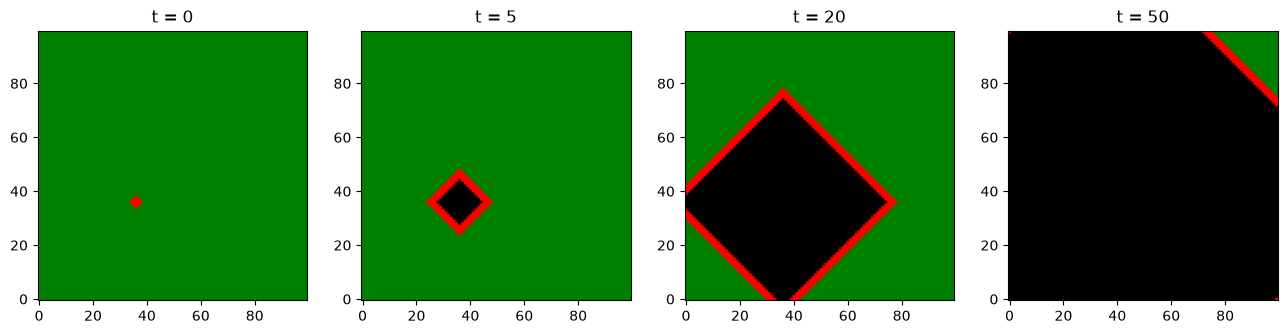

In [20]:
colors = ListedColormap(["green", "red", "black"])
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, t in zip(axes, [0, 5, 20, 50]):
    ax.imshow(fire_at(t), origin="lower", cmap=colors, vmin=0, vmax=2)
    ax.set_title(f"t = {t}")
plt.show()